# 05 — Modelo predictivo 2027: backtest y pronóstico por sección

**Pregunta de investigación**: ¿se puede predecir el resultado electoral de 2027
(diputados federales) a partir de la historia electoral y sociodemográfica por sección?

**Arquitectura de dos componentes** (la validada por el backtest):
1. **Nivel nacional**: un *escenario* definido por el usuario — los datos territoriales
   casi no predicen el swing agregado.
2. **Distribución territorial**: la composición 2024 de cada sección, calibrada (rakeada)
   al escenario nacional.

**Transiciones de calibración** (presidencial→intermedia, análogas a 2024→2027):
2012→2015 y 2018→2021. Advertencias: falacia ecológica (modelamos áreas, no votantes),
la oferta partidista de 2027 incluirá partidos nuevos sin historial (PAZ, Somos México),
y las coaliciones cambian entre elecciones.

In [1]:
import sys, os
sys.path.insert(0, os.path.join("..", "src"))
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

PROCESADOS = os.path.join("..", "data", "processed")
FIGURAS = os.path.join("..", "figuras")
os.makedirs(FIGURAS, exist_ok=True)

sec = gpd.read_file(os.path.join("..", "data", "upload", "mgsan_ext", "SECCION.shp"))
sec["id"] = sec["ENTIDAD"].astype(int).astype(str).str.zfill(2) + sec["SECCION"].astype(int).astype(str).str.zfill(4)
sec = sec[["id", "geometry"]].to_crs("EPSG:4326")
print(f"{len(sec):,} secciones cartografiadas")


71,541 secciones cartografiadas


## 1. Backtest honesto: ¿qué tan bien predice el swing territorial?

In [2]:
bt = pd.read_csv(os.path.join(PROCESADOS, "backtest_resumen.csv"), index_col=0)
display(bt.round(2))
lam = pd.read_csv(os.path.join(PROCESADOS, "backtest_lambda.csv"), index_col=0)
display(lam.round(2))

,MAE_modelo_%,MAE_persistencia_%
2012->2015 entrenó / 2018->2021 probó,35.34,37.22
2018->2021 entrenó / 2012->2015 probó,34.55,55.10


,12->15 entrena / 18->21 prueba,18->21 entrena / 12->15 prueba
0.00,26.60,31.30
0.25,27.42,31.40
0.50,29.29,31.99
0.75,32.00,33.05
1.00,35.34,34.55


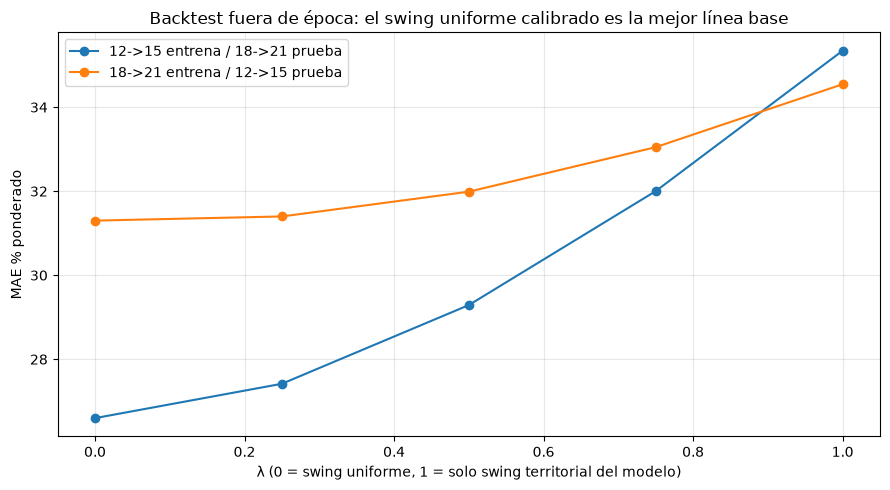

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
lam.plot(marker="o", ax=ax)
ax.set_xlabel("λ (0 = swing uniforme, 1 = solo swing territorial del modelo)")
ax.set_ylabel("MAE % ponderado")
ax.set_title("Backtest fuera de época: el swing uniforme calibrado es la mejor línea base", fontsize=12)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURAS, "backtest_lambda.png"), dpi=150, bbox_inches="tight")
plt.show()

**Resultado central del backtest**:
- El modelo territorial **bate a la persistencia** en ambas direcciones
  (34.6% vs 55.1% y 35.3% vs 37.2%), pero **pierde contra el swing uniforme
  calibrado** (λ=0 es óptimo en ambas direcciones).
- Interpretación: con solo dos transiciones pres→intermedia, el patrón
  territorial aprendido en una era política (PRI-hegemónica 2012-2015) no
  generaliza bien a otra era (morenista 2018-2021). La distribución
  territorial de 2024 ya contiene la señal territorial; el valor agregado
  de las covariables está en describir, no en predecir el swing.
- Consecuencia de diseño: el pronóstico 2027 usa **composición 2024 + raking
  a escenarios** como línea base principal, con intervalos conformales
  derivados de los errores del backtest.

## 2. Escenarios nacionales 2027

In [4]:
import modelo_2027 as m
from pronostico_2027 import construir_escenarios
nac24, nac18, nac21, delta, escenarios = construir_escenarios()

filas = []
for nombre, obj in escenarios.items():
    emitido = obj.drop(["abstencion"]).sum()
    fila = {"escenario": nombre, "participacion_%": 100 * emitido}
    for p in m.PARTIDOS:
        fila[p] = 100 * obj[p] / emitido
    fila["oficialismo"] = fila["morena"] + fila["pvem"] + fila["pt"]
    fila["oposicion"] = fila["pan"] + fila["pri"] + fila["prd"]
    filas.append(fila)
tab = pd.DataFrame(filas).set_index("escenario").round(1)
display(tab)

emitido24 = nac24.drop(["abstencion"]).sum()
print("2024 (referencia, % del voto emitido):",
      {p: f"{100*nac24[p]/emitido24:.1f}" for p in ["morena","pan","pri","pvem","pt","mc"]})
print("2021 (última intermedia, % del voto emitido):",
      {p: f"{100*nac21[p]/nac21.drop(['abstencion']).sum():.1f}" for p in ["morena","pan","pri","pvem","pt","mc"]})

,participacion_%,pan,pri,prd,pvem,pt,mc,morena,otros,oficialismo,oposicion
escenario,,,,,,,,,,,
inercia_intermedia,51.6,16.1,11.2,0.5,9.8,5.2,14.0,40.1,0.2,55.0,27.8
oficialismo_resistente,56.2,16.4,11.4,1.6,9.1,5.4,12.0,40.5,0.2,55.0,29.5
oposicion_recupera,47.3,15.6,10.8,0.2,10.5,4.9,16.2,39.2,0.2,54.5,26.6


2024 (referencia, % del voto emitido): {'morena': '41.0', 'pan': '16.7', 'pri': '11.7', 'pvem': '8.5', 'pt': '5.5', 'mc': '10.3'}
2021 (última intermedia, % del voto emitido): {'morena': '33.8', 'pan': '18.0', 'pri': '18.6', 'pvem': '5.3', 'pt': '3.4', 'mc': '6.7'}


Los escenarios aplican el cambio histórico observado 2018→2021 (caída de
participación de ~9 puntos, erosión del oficialismo, alza de MC) al punto de
partida 2024, con tres intensidades. Son supuestos editables en
`src/pronostico_2027.py` — **el nivel nacional es escenario, no predicción**.

## 3. Pronóstico por sección

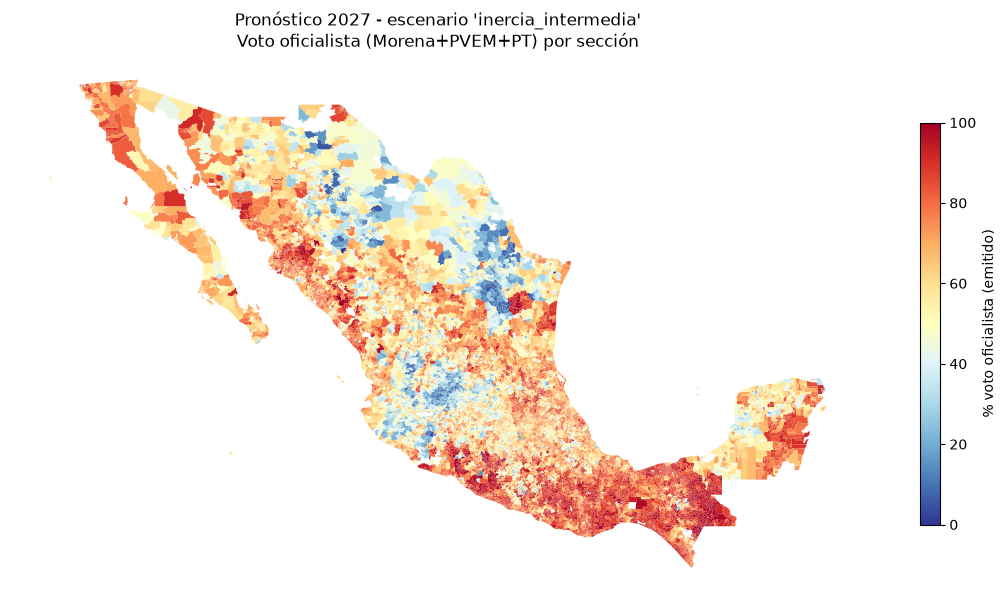

In [5]:
pron = pd.read_csv(os.path.join(PROCESADOS, "pronostico_2027_seccion.csv"),
                  dtype={"id": str}, index_col="id")
sem = pd.read_csv(os.path.join(PROCESADOS, "pronostico_2027_semiancho.csv"),
                  index_col=0).iloc[:, 0]

esc = "inercia_intermedia"
g = sec.merge(pron, on="id", how="inner")
g["oficialismo"] = 100 * (g[f"{esc}_morena"] + g[f"{esc}_pvem"] + g[f"{esc}_pt"]) / \
    (1 - g[f"{esc}_abstencion"] - g[f"{esc}_nulos"])
g["oficialismo_2024"] = 100 * pron.get("dummy", 0) * 0  # placeholder

fig, ax = plt.subplots(figsize=(11, 7))
g.plot(column="oficialismo", ax=ax, legend=True, cmap="RdYlBu_r",
       legend_kwds={"shrink": 0.6, "label": "% voto oficialista (emitido)"})
ax.set_title(f"Pronóstico 2027 - escenario '{esc}'\nVoto oficialista (Morena+PVEM+PT) por sección", fontsize=12)
ax.set_axis_off()
plt.tight_layout()
plt.savefig(os.path.join(FIGURAS, "pronostico_2027_oficialismo.png"), dpi=150, bbox_inches="tight")
plt.show()

ganador_2027
morena    51153
pan        8406
mc         5276
pvem       2900
pri        2840
pt          674
prd          28
Name: count, dtype: int64


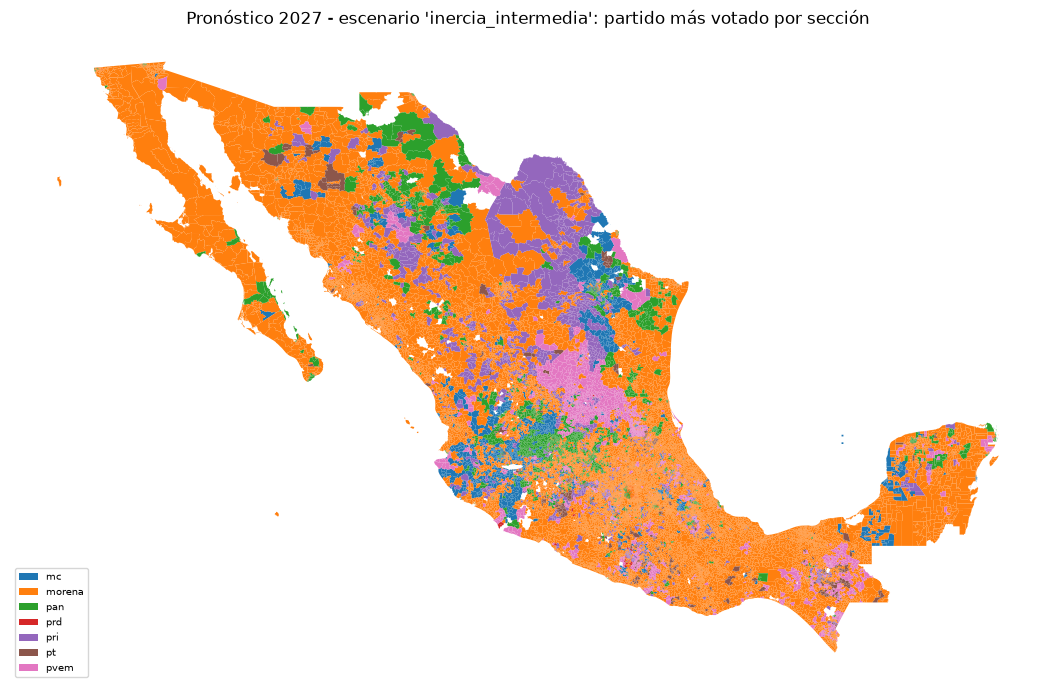

In [6]:
# Ganador por sección en el escenario base
partidos = ["pan", "pri", "prd", "pvem", "pt", "mc", "morena", "otros"]
g["ganador_2027"] = g[[f"{esc}_{p}" for p in partidos]].idxmax(axis=1).str.replace(f"{esc}_", "")
print(g["ganador_2027"].value_counts())

fig, ax = plt.subplots(figsize=(11, 7))
g.plot(column="ganador_2027", ax=ax, categorical=True, legend=True,
       cmap="tab10", legend_kwds={"loc": "lower left", "fontsize": 7})
ax.set_title(f"Pronóstico 2027 - escenario '{esc}': partido más votado por sección", fontsize=12)
ax.set_axis_off()
plt.tight_layout()
plt.savefig(os.path.join(FIGURAS, "pronostico_2027_ganador.png"), dpi=150, bbox_inches="tight")
plt.show()

## 4. Incertidumbre (intervalos conformales del backtest)

Semiancho 90% por componente (puntos de la lista nominal):


,semiancho_90pct
pan,10.3
pri,10.2
prd,2.7
pvem,3.3
pt,2.3
mc,6.7
morena,19.1
otros,4.9
nulos,1.4
abstencion,16.2


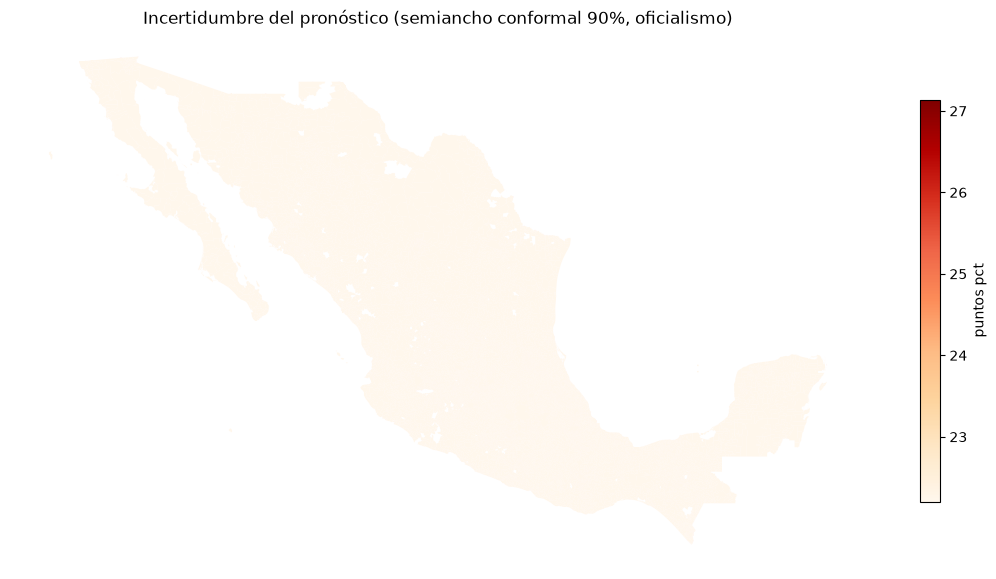

In [7]:
print("Semiancho 90% por componente (puntos de la lista nominal):")
display((100 * sem).round(1).to_frame("semiancho_90pct"))
# mapa de incertidumbre del oficialismo: semiancho morena+pvem+pt (aprox suma en el peor caso)
g["incertidumbre"] = 100 * (sem.get("morena", 0.19) + sem.get("pvem", 0.03) + sem.get("pt", 0.02))
fig, ax = plt.subplots(figsize=(11, 7))
g.plot(column="incertidumbre", ax=ax, legend=True, cmap="OrRd",
       legend_kwds={"shrink": 0.6, "label": "puntos pct"})
ax.set_title("Incertidumbre del pronóstico (semiancho conformal 90%, oficialismo)", fontsize=12)
ax.set_axis_off()
plt.tight_layout()
plt.savefig(os.path.join(FIGURAS, "pronostico_2027_incertidumbre.png"), dpi=150, bbox_inches="tight")
plt.show()

## 5. Conclusiones honestas

**Qué SÍ se puede anticipar de 2027 con estos datos:**
- Dado un escenario nacional, la geografía del voto: bastiones, zonas competitivas
  y el mapa ganador por sección (la persistencia territorial es alta: ρ 0.38-0.71).
- La participación por sección (la caída intermedia es territorialmente estable).

**Qué NO se puede predecir:**
- El nivel nacional: es un escenario, no una predicción. Cualquier cifra
  agregada depende de supuestos exógenos (aprobación, candidaturas, alianzas).
- El voto a partidos nuevos (PAZ, Somos México) sin historial.
- Cambios de oferta (coaliciones nuevas) que rompen la serie histórica.

**Evidencia**: el backtest fuera de época muestra que el swing uniforme
calibrado (MAE 26.6%) supera al modelo territorial (35.3%) y a la persistencia
(37.2%). La lección metodológica: con dos transiciones, la señal territorial
de 2024 es el mejor predictor de la distribución territorial de 2027.